In [ ]:
# 13. Construct a Feedforward Neural Network to recognize different ASL 
# alphabet hand gestures. Train the model and display training accuracy, 
# testing accuracy and loss graph. Use – Dataset - Sign Language MNIST 

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

In [2]:
# Load training and testing datasets
train_data = pd.read_csv('sign_mnist_train.csv')
test_data = pd.read_csv('sign_mnist_test.csv')

# Separate images and labels
X_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values

X_test = test_data.drop('label', axis=1).values
y_test = test_data['label'].values

# Display dataset shapes
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (27455, 784)
Testing Data: (7172, 784)


In [3]:
# Map labels into consecutive values from 0 to 23
classes = np.unique(y_train)
label_map = {label: i for i, label in enumerate(classes)}

y_train = np.array([label_map[label] for label in y_train])
y_test = np.array([label_map[label] for label in y_test])

# Normalize pixel values between 0 and 1
X_train = X_train / 255.0
X_test = X_test / 255.0

# Flatten images into 784 values
X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (27455, 784)
Testing Shape: (7172, 784)


In [4]:
# Create Feedforward Neural Network
model = tf.keras.Sequential([
    # Input layer
    tf.keras.layers.Input(shape=(784,)),

    # Hidden layers
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),

    # Output layer for 24 ASL alphabet classes
    tf.keras.layers.Dense(24, activation='softmax')
])

# Display model summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 24)                  │           1,560 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 110,296 (430.84 KB)

 Trainable params: 110,296 (430.84 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# Compile the model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [6]:
# Train the model
history = model.fit(X_train, y_train,
                    epochs=10,
                    batch_size=128,
                    validation_split=0.2)

Epoch 1/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.2611 - loss: 2.5169 - val_accuracy: 0.4285 - val_loss: 1.9036
Epoch 2/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.4926 - loss: 1.6589 - val_accuracy: 0.5804 - val_loss: 1.3923
Epoch 3/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6035 - loss: 1.2913 - val_accuracy: 0.6607 - val_loss: 1.1164
Epoch 4/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.6787 - loss: 1.0659 - val_accuracy: 0.7104 - val_loss: 0.9332
Epoch 5/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.7258 - loss: 0.9008 - val_accuracy: 0.7547 - val_loss: 0.7892
Epoch 6/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.7680 - loss: 0.7708 - val_accuracy: 0.7913 - val_loss: 0.6805
Epoch 7/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8006 - loss: 0.6659 - val_accuracy: 0.8186 - val_loss: 0.5990
Epoch 8/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.8317 - loss: 0.5778 - val_accuracy:

In [7]:
# Display final training accuracy
train_accuracy = history.history['accuracy'][-1]
print("Training Accuracy:", train_accuracy * 100, "%")

# Evaluate model on testing data
test_loss, test_accuracy = model.evaluate(X_test, y_test)

# Display testing accuracy
print("Testing Accuracy:", test_accuracy * 100, "%")

Training Accuracy: 87.4567449092865 %
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6885 - loss: 1.0437
Testing Accuracy: 68.85108947753906 %


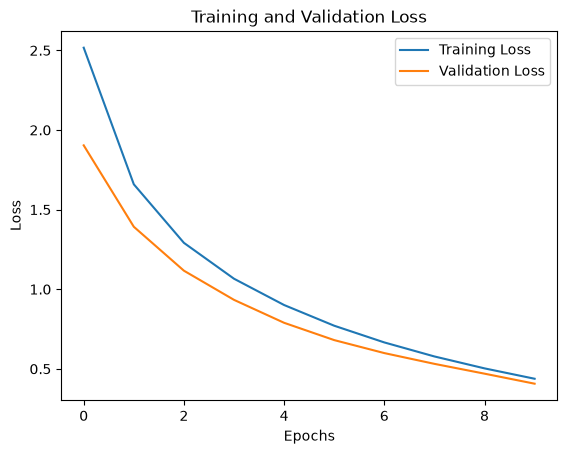

In [8]:
# Plot training and validation loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

# Add graph details
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()